In [ ]:
import glob
import os
import time
import warnings
import sklearn
import shap
import xgboost as xgb
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from xgboost import XGBClassifier

C:\Users\admin\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
def features_ml_models(X, y, random_seed, is_binary=False):
    """Train and evaluate ML models on feature data, extracting both metrics and confusion matrices.

    Args:
        X (pd.DataFrame): Feature matrix
        y (pd.Series): Target variable (either binary or multiclass)
        random_seed (int): Random seed for train/test split
        is_binary (bool): Whether this is binary classification

    Returns:
        tuple: (metrics_df, confusion_df) with model performance metrics and confusion matrix data
    """
    # Encode target variables
    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y)

    # Special handling for binary classification to ensure proper encoding
    if is_binary and len(target_encoder.classes_) == 2:
        # Ensure "Active" is encoded as 1 and "Inactive" as 0 if these are the class names
        if (
            "Active" in target_encoder.classes_
            and "Inactive" in target_encoder.classes_
        ):
            if target_encoder.transform(["Active"])[0] != 1:
                target_encoder.classes_ = target_encoder.classes_[::-1]
                y_encoded = target_encoder.transform(y)

        # Train and test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, stratify=y_encoded, test_size=0.25, random_state=random_seed
    )

    # Define the models
    models = {
        "RF": RandomForestClassifier(n_estimators=100, random_state=42),
        "XGB": XGBClassifier(random_state=42),
        #"SVC": SVC(kernel="rbf", cache_size=1000, probability=True, random_state=42),
    }

    # Create lists to store the results and confusion matrix data
    metrics_results = []
    confusion_data = []

    # Iterate over the models
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for model_name, model in models.items():
            start_time = time.time()


            
            # Fit the model with 
            model.fit(X_train, y_train )

            # Predictions
            y_pred = model.predict(X_test)
            y_pred_proba = model.predict_proba(X_test)

            # Calculate accuracy
            accuracy = model.score(X_test, y_test)

            # Calculate ROC AUC - handle binary and multiclass differently
            if is_binary:
                roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
            else:
                roc_auc = roc_auc_score(
                    y_test, y_pred_proba, multi_class="ovr", average="weighted"
                )

            # Calculate balanced accuracy
            balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

            # Calculate F1 score
            f1 = f1_score(y_test, y_pred, average="weighted")

            # Calculate precision
            precision = precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            # Calculate recall
            recall = recall_score(y_test, y_pred, average="weighted")

            # SHAP values 

            if model_name == "XGB":
                print("XGB")
                explainer = shap.TreeExplainer(model)
                explanation = explainer(X_test)

                shap_values = explanation.values
                # make sure the SHAP values add up to marginal predictions
                np.abs(shap_values.sum(axis=1) + explanation.base_values - y_pred).max()
                shap.summary_plot(explanation)

            if model_name == "RF":
                print("RF")
                explainer = shap.TreeExplainer(model)
                shap_values = explainer.shap_values(X_test)

                # make sure the SHAP values add up to marginal predictions
                shap.summary_plot(shap_values, X_test)


            train_time = time.time() - start_time

            # Append the metrics to the results list
            metrics_results.append(
                {
                    "model": model_name,
                    "roc_auc": roc_auc,
                    "accuracy": accuracy,
                    "balanced_acc": balanced_accuracy,
                    "f1_score": f1,
                    "precision": precision,
                    "recall": recall,
                    "time": train_time,
                }
            )

            # Get and process confusion matrix
            cm = confusion_matrix(y_test, y_pred)

            # Convert confusion matrix to DataFrame format
            for i in range(len(cm)):
                for j in range(len(cm)):
                    confusion_data.append(
                        {
                            "model": model_name,
                            "actual_label": i,
                            "predicted_label": j,
                            "count": cm[i][j],
                        }
                    )

            print(f"{model_name} Done")

    # Convert results to DataFrames
    metrics_df = pd.DataFrame(metrics_results)
    confusion_df = pd.DataFrame(confusion_data)

    # Map the encoded labels back to original classes if possible
    original_classes = target_encoder.classes_
    if len(confusion_df) > 0:
        confusion_df["actual_label"] = confusion_df["actual_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )
        confusion_df["predicted_label"] = confusion_df["predicted_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )

    return metrics_df, confusion_df

In [ ]:
def features_ml_models_weighted(X, y, random_seed, is_binary=False):
    """Train and evaluate ML models on feature data, extracting both metrics and confusion matrices.

    Args:
        X (pd.DataFrame): Feature matrix
        y (pd.Series): Target variable (either binary or multiclass)
        random_seed (int): Random seed for train/test split
        is_binary (bool): Whether this is binary classification

    Returns:
        tuple: (metrics_df, confusion_df) with model performance metrics and confusion matrix data
    """
    # Encode target variables
    target_encoder = LabelEncoder()
    y_encoded = target_encoder.fit_transform(y)

    # Special handling for binary classification to ensure proper encoding
    if is_binary and len(target_encoder.classes_) == 2:
        # Ensure "Active" is encoded as 1 and "Inactive" as 0 if these are the class names
        if (
            "Active" in target_encoder.classes_
            and "Inactive" in target_encoder.classes_
        ):
            if target_encoder.transform(["Active"])[0] != 1:
                target_encoder.classes_ = target_encoder.classes_[::-1]
                y_encoded = target_encoder.transform(y)

        # Train and test split
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, stratify=y_encoded, test_size=0.25, random_state=random_seed
    )

    # Define the models
    models = {
        "RF": RandomForestClassifier(n_estimators=100, random_state=42),
        "XGB": XGBClassifier(random_state=42),
        #"SVC": SVC(kernel="rbf", cache_size=1000, probability=True, random_state=42),
    }

    # Create lists to store the results and confusion matrix data
    metrics_results = []
    confusion_data = []

    # Iterate over the models
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for model_name, model in models.items():
            start_time = time.time()


            
            # Fit the model with 
            model.fit(X_train, y_train, sample_weight=compute_sample_weight("balanced", y)  )

            # Predictions
            y_pred = model.predict(X_test)
            y_pred_proba = model.predict_proba(X_test)

            # Calculate accuracy
            accuracy = model.score(X_test, y_test)

            # Calculate ROC AUC - handle binary and multiclass differently
            if is_binary:
                roc_auc = roc_auc_score(y_test, y_pred_proba[:, 1])
            else:
                roc_auc = roc_auc_score(
                    y_test, y_pred_proba, multi_class="ovr", average="weighted"
                )

            # Calculate balanced accuracy
            balanced_accuracy = balanced_accuracy_score(y_test, y_pred)

            # Calculate F1 score
            f1 = f1_score(y_test, y_pred, average="weighted")

            # Calculate precision
            precision = precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            # Calculate recall
            recall = recall_score(y_test, y_pred, average="weighted")

            # SHAP values 

            if model_name == "XGB":
                print("XGB")
                explainer = shap.TreeExplainer(model)
                explanation = explainer(X_test)

                shap_values = explanation.values
                # make sure the SHAP values add up to marginal predictions
                np.abs(shap_values.sum(axis=1) + explanation.base_values - y_pred).max()
                shap.summary_plot(explanation)

            if model_name == "RF":
                print("RF")
                explainer = shap.TreeExplainer(model)

                explanation = explainer(X_test)

                shap_values = explanation.values
                #shap_values = explainer.shap_values(X_test)

                # make sure the SHAP values add up to marginal predictions
                shap.summary_plot(shap_values, X_test)


            train_time = time.time() - start_time

            # Append the metrics to the results list
            metrics_results.append(
                {
                    "model": model_name,
                    "roc_auc": roc_auc,
                    "accuracy": accuracy,
                    "balanced_acc": balanced_accuracy,
                    "f1_score": f1,
                    "precision": precision,
                    "recall": recall,
                    "time": train_time,
                }
            )

            # Get and process confusion matrix
            cm = confusion_matrix(y_test, y_pred)

            # Convert confusion matrix to DataFrame format
            for i in range(len(cm)):
                for j in range(len(cm)):
                    confusion_data.append(
                        {
                            "model": model_name,
                            "actual_label": i,
                            "predicted_label": j,
                            "count": cm[i][j],
                        }
                    )

            print(f"{model_name} Done")

    # Convert results to DataFrames
    metrics_df = pd.DataFrame(metrics_results)
    confusion_df = pd.DataFrame(confusion_data)

    # Map the encoded labels back to original classes if possible
    original_classes = target_encoder.classes_
    if len(confusion_df) > 0:
        confusion_df["actual_label"] = confusion_df["actual_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )
        confusion_df["predicted_label"] = confusion_df["predicted_label"].apply(
            lambda x: original_classes[x] if x < len(original_classes) else x
        )

    return metrics_df, confusion_df

In [10]:
txtfiles = []
for file in glob.glob("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables/*_allv.csv"):
    txtfiles.append(file)

print(txtfiles)

['//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\WA_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\HE_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\AG_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\TA_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\LH_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\MF_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\PM_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\MP_allv.csv', '//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables\\HP_al

In [7]:
variables = ["PCA_1", "PCA_2", "HM", "trade", "MPD"]

- XGBoost better than RF in actual(1) predicted (0) but not from far in terms of numbers for S2, very equal rf and xgboost in S
- Shap values don't agree with the % of variabel importance, if they do usually in S2 (1 agree in S1, HO; 4 agree in S2)

In [ ]:
# 1m 30 to run ! 

for file in txtfiles:
    sp = pd.read_csv(file)

    sp.head
    print(sp.loc[1, 'Taxa'])
    for S in ['S1', 'S2']:
        mask = ((sp['S'] == S))
        x = sp.loc[mask, variables]
        Y = sp.loc[mask, 'Occurrence']

        z, b = features_ml_models(x, Y, 1, is_binary=True)
        print(z)
        print(b)


In [ ]:
a = pd.read_csv("//wsl.localhost/Ubuntu/home/admin_ait/internship-snakemake-2025/results/species/AssignVariables/_allv.csv")

In [ ]:
for S in ['S1', 'S2']:
    for pa_n in range(1,10):
        mask = ((a['PA_N'] == 1 ) & (a['S'] == S) ) | ((a['PA_N'].isna()) & (a['S'] == S))
        x = a.loc[mask, variables]
        Y = a.loc[mask, 'Occurrence']

        z = features_ml_models(x, Y, 1, is_binary=True)
        print(z)




RF Done


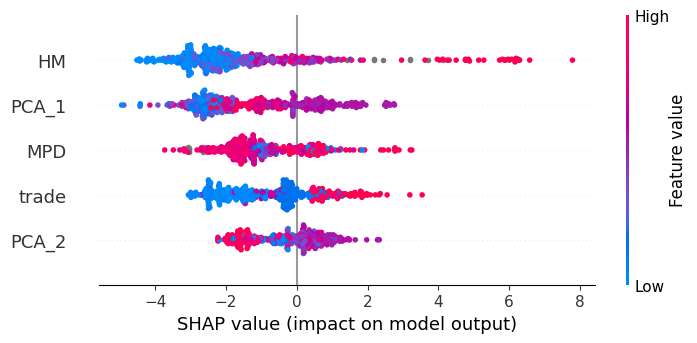

XGB Done
  model   roc_auc  accuracy  balanced_acc  f1_score  precision    recall  \
0    RF  0.997465  0.976789      0.910638  0.976323   0.976200  0.976789   
1   XGB  0.997284  0.992263      0.967021  0.992187   0.992202  0.992263   

       time  
0  0.657395  
1  0.750321  
  model  actual_label  predicted_label  count
0    RF             0                0    466
1    RF             0                1      4
2    RF             1                0      8
3    RF             1                1     39
4   XGB             0                0    469
5   XGB             0                1      1
6   XGB             1                0      3
7   XGB             1                1     44
RF Done


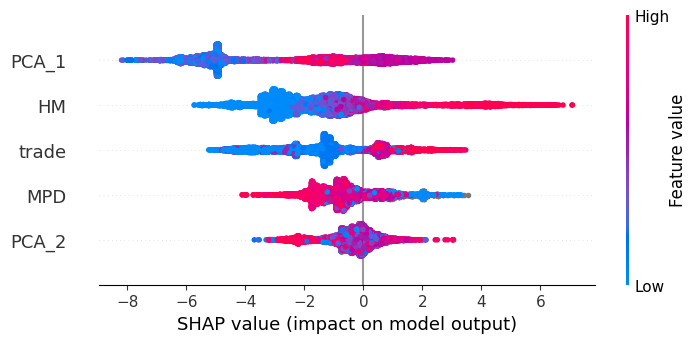

XGB Done
  model   roc_auc  accuracy  balanced_acc  f1_score  precision    recall  \
0    RF  0.995025  0.984262      0.950384  0.984230   0.984202  0.984262   
1   XGB  0.995588  0.984379      0.952755  0.984379   0.984379  0.984379   

       time  
0  7.977487  
1  3.382024  
  model  actual_label  predicted_label  count
0    RF             0                0   7734
1    RF             0                1     64
2    RF             1                0     71
3    RF             1                1    709
4   XGB             0                0   7731
5   XGB             0                1     67
6   XGB             1                0     67
7   XGB             1                1    713


In [109]:
for S in ['S1', 'S2']:
    mask = ((a['S'] == S))
    x = a.loc[mask, variables]
    Y = a.loc[mask, 'Occurrence']

    z, b = features_ml_models(x, Y, 1, is_binary=True)
    print(z)
    print(b)


RF Done


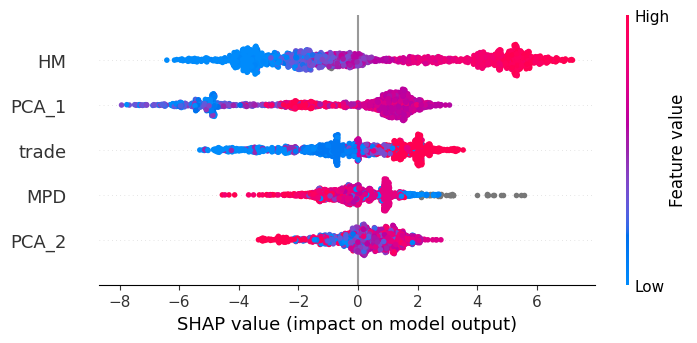

XGB Done


In [101]:
 z, b, c = features_ml_models(x, Y, 1, is_binary=True)

In [104]:
c

array([[ 0.8227598 ,  0.75127035,  2.8105915 ,  1.172413  , -0.08055723],
       [ 1.5879152 ,  1.6053782 ,  4.4677725 ,  2.0221448 ,  0.830775  ],
       [ 1.7316393 ,  0.4055537 ,  0.36153445,  0.05432508, -0.23614436],
       ...,
       [ 2.4318056 ,  1.079469  , -2.0209444 ,  2.9726403 ,  1.2616024 ],
       [-0.2970842 , -2.6482084 , -1.1076587 , -4.296618  , -1.4968648 ],
       [-4.2877803 ,  0.07634967, -0.33294848, -2.556301  , -1.3744311 ]],
      shape=(1560, 5), dtype=float32)